# Stage 3 — Fine-tuning (E1) and view-bias diagnosis

**Training** ran on Kaggle (GPU T4, ~104 s/epoch, 3 seeds × 12 epochs), with the RSNA competition attached as input:

```python
# Cell 1 — clone repo and install deps
!git clone -q https://github.com/xabieralbizu2/V1_XRay_xAI /kaggle/working/xai-cxr-shortcuts
!pip install -q torchxrayvision pydicom
sys.path.insert(0, "/kaggle/working/xai-cxr-shortcuts")

# Cell 2 — rebuild the same patient splits and the 224 px image cache
assign = pd.read_csv(REPO_ROOT / "splits" / "patient_splits.csv")
splits = build_metadata(find_data_root()).merge(assign, on="patientId", how="inner")
build_image_cache(find_data_root(), splits.patientId, cache_path)

# Cell 3 — train E1 with three seeds
for seed in [0, 1, 2]:
    train_model(TrainConfig(experiment="E1", seed=seed, num_workers=4), cache_path, splits, out_dir, get_device())
```

Checkpoints (`checkpoints/e1_seed{0,1,2}.pt`) are not versioned. Everything below runs locally.

## 1. Test AUC: overall and within each view

In [2]:
import pandas as pd
from torch.utils.data import DataLoader
from src.data import REPO_ROOT
from src.dataset import CachedCXRDataset
from src.models import predict_logits
from src.train import load_trained
from src.metrics import auc_by_group
from src.utils import get_device

DATA, CKPT = REPO_ROOT / "data", REPO_ROOT / "checkpoints"
cache_path = DATA / "processed" / "images_224.npy"
test = pd.read_csv(DATA / "predictions" / "test_b1_e0.csv")
device = get_device()

loader = DataLoader(CachedCXRDataset(cache_path, test.patientId), batch_size=64, num_workers=0)
seeds = [0, 1, 2]
for s in seeds:
    model = load_trained(CKPT / f"e1_seed{s}.pt", device)
    test[f"e1_seed{s}"] = predict_logits(model, loader, device)[:, 0]
test["e1_mean"] = test[[f"e1_seed{s}" for s in seeds]].mean(axis=1)

cols = ["p_b1", "e0_lung_opacity"] + [f"e1_seed{s}" for s in seeds] + ["e1_mean"]
results = pd.concat([auc_by_group(test, c) for c in cols])
print(results.round(3).to_string(index=False))

# mean ± std across seeds, per subset
seed_auc = results[results.model.str.match(r"e1_seed\d")]
print(seed_auc.groupby("subset").auc.agg(["mean", "std"]).round(3))

test.to_csv(DATA / "predictions" / "test_b1_e0_e1.csv", index=False)
(REPO_ROOT / "results").mkdir(exist_ok=True)
results.to_csv(REPO_ROOT / "results" / "stage3_test_auc.csv", index=False)

/Users/xabieralbizuarias/Documents/master/explicabilidad/proyecto_final/.venv-xai/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


 subset   auc  ci_low  ci_high           model
overall 0.727   0.709    0.746            p_b1
     AP 0.552   0.524    0.578            p_b1
     PA 0.545   0.504    0.588            p_b1
overall 0.779   0.762    0.794 e0_lung_opacity
     AP 0.695   0.670    0.719 e0_lung_opacity
     PA 0.747   0.713    0.778 e0_lung_opacity
overall 0.865   0.852    0.877        e1_seed0
     AP 0.817   0.798    0.836        e1_seed0
     PA 0.823   0.796    0.849        e1_seed0
overall 0.864   0.852    0.877        e1_seed1
     AP 0.817   0.797    0.836        e1_seed1
     PA 0.824   0.798    0.851        e1_seed1
overall 0.865   0.852    0.877        e1_seed2
     AP 0.816   0.797    0.835        e1_seed2
     PA 0.824   0.797    0.851        e1_seed2
overall 0.865   0.852    0.877         e1_mean
     AP 0.817   0.798    0.836         e1_mean
     PA 0.824   0.797    0.851         e1_mean
          mean    std
subset               
AP       0.817  0.000
PA       0.824  0.001
overall  0.865  0.0

## 2. Training curves

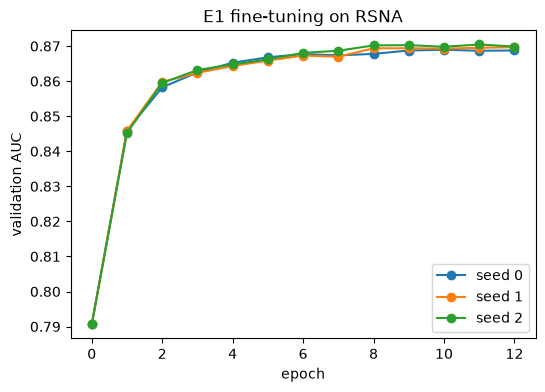

In [3]:
import matplotlib.pyplot as plt
fig_dir = REPO_ROOT / "docs" / "figures"
fig_dir.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(figsize=(6, 4))
for s in seeds:
    h = pd.read_csv(CKPT / f"e1_seed{s}_history.csv")
    ax.plot(h.epoch, h.val_auc, marker="o", label=f"seed {s}")
ax.set(xlabel="epoch", ylabel="validation AUC", title="E1 fine-tuning on RSNA")
ax.legend()
fig.savefig(fig_dir / "e1_val_auc.png", dpi=150, bbox_inches="tight")

## 3. Naive stress test
*aligned* = AP positives + PA negatives (view agrees with label); *inverted* = PA positives + AP negatives (view contradicts label).
**Confounded:** the groups also differ in difficulty (see section 4), so this is kept only for transparency.

In [4]:
from src.metrics import bootstrap_auc

models = ["p_b1", "e0_lung_opacity", "e1_mean"]
pos, ap = test.target == 1, test.view == "AP"
sets = {
    "aligned": test[(pos & ap) | (~pos & ~ap)],    # view agrees with label
    "inverted": test[(pos & ~ap) | (~pos & ap)],   # view contradicts label
}
rows = [(name, m, *bootstrap_auc(d.target, d[m]), len(d))
        for name, d in sets.items() for m in models]
stress = pd.DataFrame(rows, columns=["set", "model", "auc", "ci_low", "ci_high", "n"])
print(stress.round(3).to_string(index=False))

# Among healthy patients only: does the score separate AP from PA? (0.5 = ignores view)
healthy = test[test.target == 0]
for m in models:
    print(m, round(bootstrap_auc((healthy.view == "AP").astype(int), healthy[m])[0], 3))

stress.to_csv(REPO_ROOT / "results" / "stage3_stress_test.csv", index=False)

     set           model   auc  ci_low  ci_high    n
 aligned            p_b1 1.000   1.000    1.000 2674
 aligned e0_lung_opacity 0.884   0.871    0.898 2674
 aligned         e1_mean 0.961   0.954    0.967 2674
inverted            p_b1 0.000   0.000    0.000 1328
inverted e0_lung_opacity 0.484   0.447    0.522 1328
inverted         e1_mean 0.518   0.479    0.557 1328
p_b1 1.0
e0_lung_opacity 0.725
e1_mean 0.795


## 4. Controls
1. Class mix and lesion size per view.
2. Stress test with *Normal* negatives only.
3. **View leakage:** among *Normal* studies only, AUC of the score for AP vs PA (0.5 = the score ignores the view).

In [5]:
from src.data import find_data_root, LABELS_FILE, CLASSES_FILE

root = find_data_root()
cls = pd.read_csv(root / CLASSES_FILE).drop_duplicates("patientId")
boxes = pd.read_csv(root / LABELS_FILE).dropna(subset=["width"])
area = (boxes.width * boxes.height).groupby(boxes.patientId).sum().rename("box_area")
test = test.drop(columns=["class", "box_area"], errors="ignore")
test = test.merge(cls[["patientId", "class"]], on="patientId", how="left").merge(area, on="patientId", how="left")

# 1) Are the groups comparable?
print(pd.crosstab(test["class"], test.view, normalize="columns").round(2))
print(test[test.target == 1].groupby("view").box_area.median())

# 2) Stress test with truly normal negatives only
sub = test[(test.target == 1) | (test["class"] == "Normal")]
pos, ap = sub.target == 1, sub.view == "AP"
rows = [(name, m, *bootstrap_auc(d.target, d[m]), len(d))
        for name, d in {"aligned": sub[(pos & ap) | (~pos & ~ap)],
                        "inverted": sub[(pos & ~ap) | (~pos & ap)]}.items()
        for m in models]
print(pd.DataFrame(rows, columns=["set", "model", "auc", "ci_low", "ci_high", "n"]).round(3).to_string(index=False))

# 3) Cleanest check: among Normal images only, does the score separate AP from PA?
normal = test[test["class"] == "Normal"]
for m in models:
    print(m, [round(v, 3) for v in bootstrap_auc((normal.view == "AP").astype(int), normal[m])])


pd.DataFrame(rows, columns=["set", "model", "auc", "ci_low", "ci_high", "n"]).to_csv(
    REPO_ROOT / "results" / "stage3_stress_test_normal.csv", index=False)

view                            AP    PA
class                                   
Lung Opacity                  0.38  0.09
No Lung Opacity / Not Normal  0.48  0.42
Normal                        0.14  0.48
view
AP    110222.0
PA     58419.0
Name: box_area, dtype: float64
     set           model   auc  ci_low  ci_high    n
 aligned            p_b1 1.000   1.000    1.000 1752
 aligned e0_lung_opacity 0.964   0.956    0.971 1752
 aligned         e1_mean 0.995   0.993    0.996 1752
inverted            p_b1 0.000   0.000    0.000  452
inverted e0_lung_opacity 0.805   0.764    0.844  452
inverted         e1_mean 0.814   0.773    0.853  452
p_b1 [1.0, np.float64(1.0), np.float64(1.0)]
e0_lung_opacity [0.627, np.float64(0.587), np.float64(0.666)]
e1_mean [0.785, np.float64(0.755), np.float64(0.814)]


## 5. Operating point
Threshold chosen on **validation** at 90 % sensitivity, then applied to test. `flagged` is the sensitivity for *Lung Opacity* and the false-positive rate for the other classes.

In [6]:
import numpy as np

splits = pd.read_csv(DATA / "splits.csv")
val = splits[splits.split == "val"].reset_index(drop=True)
vloader = DataLoader(CachedCXRDataset(cache_path, val.patientId), batch_size=64, num_workers=0)
for s in seeds:
    model = load_trained(CKPT / f"e1_seed{s}.pt", device)
    val[f"e1_seed{s}"] = predict_logits(model, vloader, device)[:, 0]
val["e1_mean"] = val[[f"e1_seed{s}" for s in seeds]].mean(axis=1)

# Operating threshold chosen on validation: 90% sensitivity (screening)
thr = np.quantile(val.loc[val.target == 1, "e1_mean"], 0.10)
sigmoid = lambda z: 1 / (1 + np.exp(-z))
print("threshold (probability):", round(sigmoid(thr), 3))

test["e1_prob"] = sigmoid(test.e1_mean)
test["e1_flag"] = test.e1_mean >= thr
summary = (test.groupby(["class", "view"])
           .agg(n=("e1_prob", "size"),
                median_prob=("e1_prob", "median"),
                flagged=("e1_flag", "mean"))
           .round(3))
print(summary)
summary.to_csv(REPO_ROOT / "results" / "stage3_operating_point.csv")

threshold (probability): 0.106
                                      n  median_prob  flagged
class                        view                            
Lung Opacity                 AP     700        0.584    0.960
                             PA     202        0.206    0.718
No Lung Opacity / Not Normal AP     876        0.250    0.756
                             PA     922        0.082    0.440
Normal                       AP     250        0.035    0.184
                             PA    1052        0.011    0.028


## 6. Is the E1 vs E0 leakage difference robust?
Paired bootstrap on the same Normal studies, plus leakage per seed.

In [7]:
from sklearn.metrics import roc_auc_score

normal = test[test["class"] == "Normal"].reset_index(drop=True)
y = (normal.view == "AP").astype(int).to_numpy()
e0, e1 = normal.e0_lung_opacity.to_numpy(), normal.e1_mean.to_numpy()

rng = np.random.default_rng(0)
diffs = []
for _ in range(2000):
    idx = rng.integers(0, len(y), len(y))
    diffs.append(roc_auc_score(y[idx], e1[idx]) - roc_auc_score(y[idx], e0[idx]))
print("E1 - E0 leakage:", round(np.mean(diffs), 3), np.percentile(diffs, [2.5, 97.5]).round(3))

for s in seeds:
    print(f"seed {s}:", round(roc_auc_score(y, normal[f"e1_seed{s}"]), 3))

E1 - E0 leakage: 0.158 [0.126 0.19 ]
seed 0: 0.78
seed 1: 0.79
seed 2: 0.784


## Summary
- E1 improves on E0 overall (0.779 → 0.865) and within each view (AP 0.695 → 0.817, PA 0.747 → 0.824); seeds agree (std ≤ 0.001).
- The naive stress test (0.96 vs 0.52) is confounded by case difficulty: AP negatives are mostly *Not Normal* and PA lesions are half the size.
- **View leakage** among Normal studies: E0 0.627 [0.587–0.666] → E1 **0.785 [0.755–0.814]**. Fine-tuning amplified the view dependence.
- At a 90 %-sensitivity threshold, **18.4 % of Normal AP vs 2.8 % of Normal PA** studies are flagged as opacity.
- Open question for Stage 4: does the bias come from cues outside the lungs (H1), AP projection physics inside the lungs (H2), or less reliable Normal labels in AP (H3)?